# MusicMap
## Music Genre Classification and Pattern Discovery Using Machine Learning

**ML laboratory project · Python / scikit-learn**

We compare Decision Tree, KNN, SVM, a feed-forward ANN, and an Extra Trees benchmark on FMA-small, then investigate audio similarity and feature relevance.

**Questions:** Which model generalizes best under an artist-disjoint split? Which genres are confused? Which feature families matter? Do unsupervised clusters resemble genres?

This notebook includes real outputs from the improved experiment. The original standard-profile reports and models are preserved in baseline/. Read the report for a complete interpretation and references. Fill in your student details in the editable Word report.

### How to use this notebook

Run cells from top to bottom after installing the project requirements. The default switches display included measurements without retraining. Set **RUN_TRAINING = True** for a fresh experiment; this also rebuilds the dependent discovery analyses and report. Set **RUN_DISCOVERY = True** to rebuild analysis from the saved fitted models.

The methodological explanations describe the default **improved** profile. The optional legacy **standard** and **quick** profiles reproduce the original validation-only search with one ANN seed; they do not run grouped CV, classifier feature reduction, an ANN ensemble, or Extra Trees. Use the recorded profile label to interpret the displayed measurements.

The complete package includes prepared feature data and fitted models. With the smaller code-and-results package or a source-only checkout, run **musicmap improve** first or set **RUN_TRAINING = True**. Missing data are prepared from the official 342 MiB metadata archive; the large audio archive is unnecessary. All computation uses the CPU.

In [1]:
from pathlib import Path
import json
import sys
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image, FileLink
from threadpoolctl import threadpool_limits

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").exists() and (path / "src/musicmap").exists()
)
sys.path.insert(0, str(ROOT / "src"))
from musicmap.data import prepare_data
from musicmap.experiment import build_model, parameter_grid, run_experiment, MODEL_NAMES
from musicmap.improvement import run_improvement
from musicmap.discovery import run_discovery, nearest_tracks
from musicmap.reporting import generate_report

RUN_TRAINING = False
RUN_DISCOVERY = False
PROFILE = "improved"
SEED = 42
THREADS = 2
REPORTS = ROOT / "reports"
pd.set_option("display.max_colwidth", 90)
print("Project root:", ROOT)


Project root: /workspace/musicmap


### 1. Load and validate FMA-small

The original tracks CSV has two header levels and the features CSV has three. The data module reads them in chunks, filters the small subset, and aligns rows by track ID. Only numeric audio descriptors become predictors; genre, artist, title, and split metadata are separate.

The original metadata archive is checked against FMA's published SHA-1. The compact prepared files have their own SHA-256 checksums. Completely missing feature rows would be removed and recorded; partially missing values are left for training-fitted imputation.

In [2]:
dataset = prepare_data(ROOT)
print(f"Feature matrix: {dataset.X.shape[0]:,} tracks × {dataset.X.shape[1]} descriptors")
print("Missing feature values:", int(dataset.X.isna().sum().sum()))
display(dataset.metadata.head())
display(pd.DataFrame({
    "columns": pd.Series(dataset.manifest["feature_family_sizes"])
}).rename_axis("audio_feature_family"))


Using verified prepared FMA-small data.


Feature matrix: 8,000 tracks × 518 descriptors
Missing feature values: 0


,genre,split,artist_id,title,artist,album_id
track_id,,,,,,
2,Hip-Hop,training,1,Food,AWOL,1
5,Hip-Hop,training,1,This World,AWOL,1
10,Pop,training,6,Freeway,Kurt Vile,6
140,Folk,training,54,Queen Of The Wires,Alec K. Redfearn & the Eyesores,61
141,Folk,training,54,Ohio,Alec K. Redfearn & the Eyesores,60


,columns
audio_feature_family,
mfcc,140
chroma_cqt,84
chroma_cens,84
chroma_stft,84
spectral_contrast,49
tonnetz,42
rmse,7
spectral_centroid,7
spectral_bandwidth,7


### 2. Inspect class balance and artist separation

FMA-small contains eight genres, each with 1,000 tracks. Its supplied partitions have 6,400 training, 800 validation, and 800 test tracks.

A random split of tracks can put an artist's recordings on both sides of evaluation. We preserve the official partitions and explicitly audit artist IDs.

split,training,validation,test
genre,,,
Electronic,800,100,100
Experimental,800,100,100
Folk,800,100,100
Hip-Hop,800,100,100
Instrumental,800,100,100
International,800,100,100
Pop,800,100,100
Rock,800,100,100


,shared_artist_ids
training__validation,0
training__test,0
validation__test,0


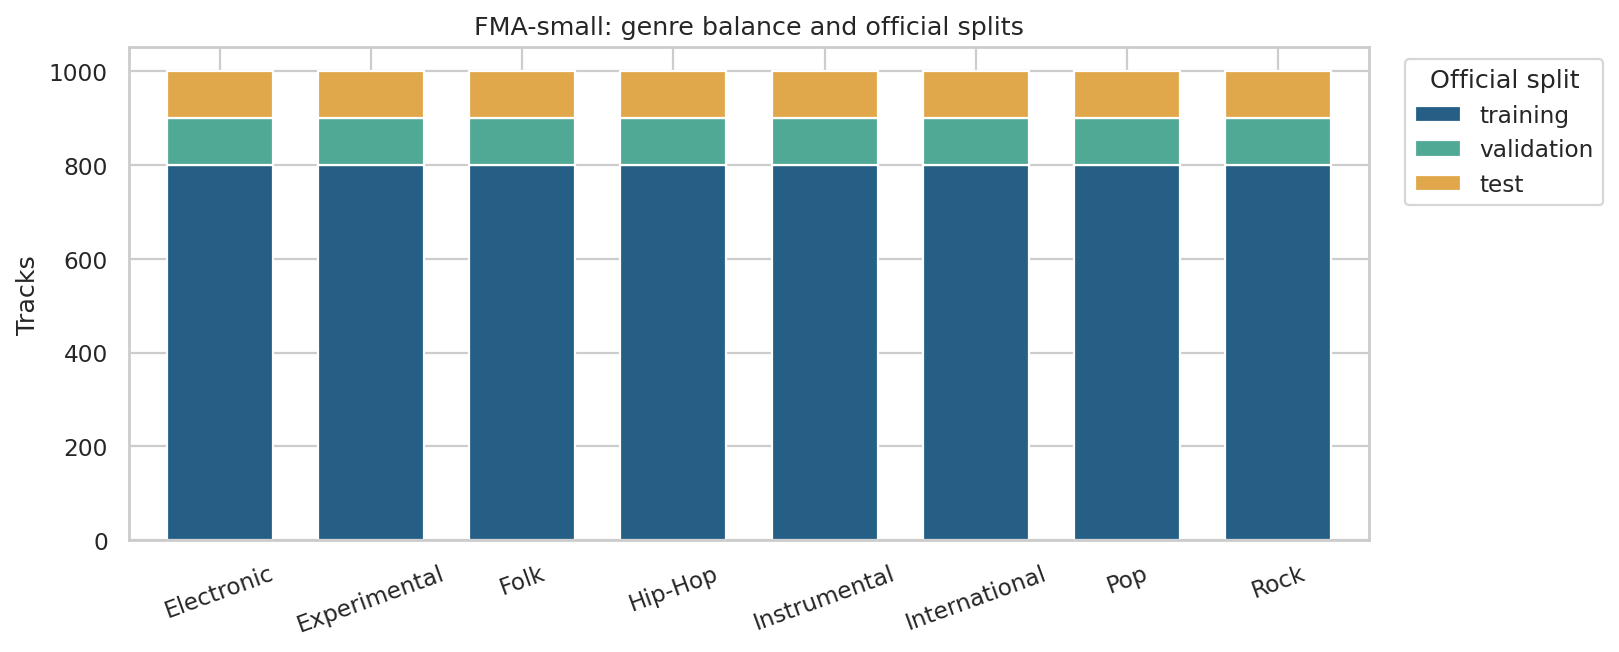

In [3]:
balance = pd.crosstab(dataset.y, dataset.metadata["split"])[["training", "validation", "test"]]
display(balance)
audit = dataset.manifest["split_audit"]
display(pd.Series(audit["artist_overlap_counts"], name="shared_artist_ids").to_frame())
assert all(count == 0 for count in audit["artist_overlap_counts"].values())
assert audit["missing_artist_ids"] == 0
display(Image(filename=str(REPORTS / "figures/genre_balance.png"), width=900))


### 3. Preprocessing, feature reduction, and classifiers

Every candidate learns its preprocessing within each artist-grouped fitting fold: **median imputation → constant-column removal → standard or quantile scaling → optional feature selection/PCA → classifier**.

Standard scaling learns each feature's mean and standard deviation. The improved search also tests a quantile-to-normal transformation for skewed distributions, ANOVA descriptor selection, and PCA dimensionality reduction. All fitted transformations remain inside the cross-validation pipeline. The fixed 50-component PCA map is a separate exploratory representation.

The ANN uses scikit-learn multilayer perceptrons with ReLU/Adam and early stopping. The selected architecture is evaluated at seeds 42, 43, and 44; the final ANN averages their class probabilities rather than choosing a lucky seed. Each network has an internal track holdout within its fitting partition. Outer assessment folds stay artist-disjoint. Label encoding preserves readable predictions.

In [4]:
train_ids = dataset.ids("training")
validation_ids = dataset.ids("validation")
X_train, y_train = dataset.X.loc[train_ids], dataset.y.loc[train_ids]
X_validation, y_validation = dataset.X.loc[validation_ids], dataset.y.loc[validation_ids]

example_pipeline = build_model("SVM (RBF)", {"C": 10.0, "gamma": "scale"}, seed=SEED)
print(example_pipeline)
if PROFILE == "improved":
    print("Improved search: artist-grouped CV, all/select/PCA features, standard/quantile scaling.")
    if (REPORTS / "cv_results.csv").exists():
        search_rows = pd.read_csv(REPORTS / "cv_results.csv")
        display(search_rows.groupby("model").size().rename("recorded configurations").to_frame())
else:
    display(pd.DataFrame([
        {"model": name, "candidates": len(parameter_grid(name, PROFILE)),
         "grid": parameter_grid(name, PROFILE)}
        for name in MODEL_NAMES
    ]))


Pipeline(steps=[('imputer',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('variance', VarianceThreshold()), ('scaler', StandardScaler()),
                ('model', SVC(C=10.0, cache_size=256))])
Improved search: artist-grouped CV, all/select/PCA features, standard/quantile scaling.


,recorded configurations
model,
ANN (MLP),14
Decision Tree,6
Dummy baseline,1
Extra Trees,4
KNN,17
SVM (RBF),52


### 4. Tune, lock selection, refit, evaluate

Tune every configuration using **three-fold StratifiedGroupKFold within the official 6,400 training tracks**, with artist IDs as groups. Select one configuration per family by mean CV macro F1, then select the winning algorithm using the official validation set. The ANN is a fixed ensemble of its three recorded seeds. A majority-class dummy model supplies context.

Save all choices before requesting this run's test features and labels. Refit selected configurations on 7,200 training/validation tracks, then evaluate on the official 800 test tracks.

The original test scores were already viewed in the first project. Updated scores are an **extended benchmark comparison**, not a pristine new confirmatory holdout. The search uses training-fold and validation scores; a fresh artist-disjoint confirmation dataset would strengthen claims about generalization gains.

Validation-selected winner: ANN (MLP)
Profile: improved | seed: 42


,model,train_f1_macro,validation_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,ANN (MLP),0.9175,0.5613,0.4725,0.4698,0.4725,0.4695
1,SVM (RBF),0.8107,0.5575,0.4975,0.4916,0.4975,0.4925
2,Extra Trees,0.9998,0.5430,0.4812,0.4754,0.4812,0.4760
3,KNN,0.9998,0.4944,0.3825,0.3887,0.3825,0.3674
4,Decision Tree,0.6599,0.3656,0.3425,0.3488,0.3425,0.3437
5,Dummy baseline,0.0278,0.0278,0.1250,0.0156,0.1250,0.0278


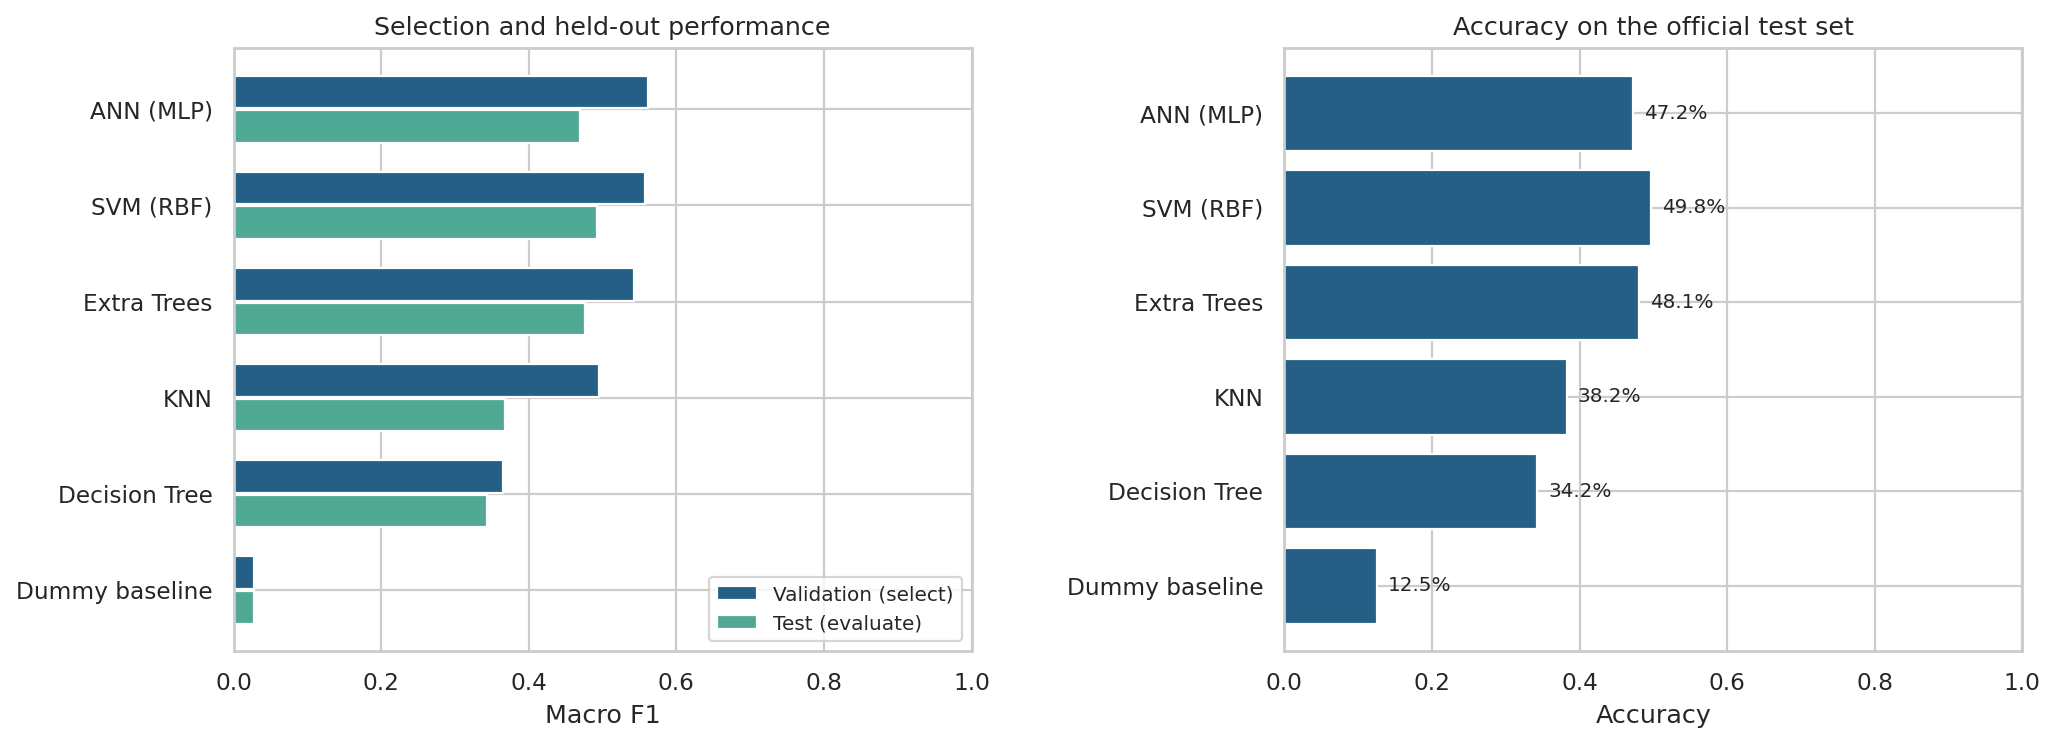

In [5]:
if RUN_TRAINING:
    if PROFILE == "improved":
        run_improvement(dataset, REPORTS, seed=SEED, threads=THREADS, cv_folds=3)
    else:
        run_experiment(dataset, REPORTS, profile=PROFILE, seed=SEED, threads=THREADS)
if RUN_TRAINING or RUN_DISCOVERY:
    recorded_run = json.loads((REPORTS / "run_info.json").read_text())
    run_discovery(dataset, REPORTS, seed=recorded_run["seed"], threads=THREADS, repeats=5)
    generate_report(dataset, REPORTS)

comparison = pd.read_csv(REPORTS / "model_comparison.csv")
selection = json.loads((REPORTS / "selection.json").read_text())
run_info = json.loads((REPORTS / "run_info.json").read_text())
print("Validation-selected winner:", selection["champion"])
print("Profile:", run_info["profile"], "| seed:", run_info["seed"])
display(comparison[[
    "model", "train_f1_macro", "validation_f1_macro",
    "test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro"
]].round(4))
display(Image(filename=str(REPORTS / "figures/model_comparison.png"), width=1100))


### Cross-validation, ANN variability, and the preserved baseline

Inspect all CV scores, the artist-overlap audit, and the three ANN seed results. CV standard deviations summarize fold variability; they are not confidence intervals. The final ANN uses all three seeds with equal weight.

The comparison below reports observed changes against the preserved first experiment. Test scores were already seen previously, so the new result is an extended comparison.

,model,candidate_id,parameters,cv_mean_f1,cv_std_f1,cv_fold_f1,fit_seconds,warnings
68,SVM (RBF),45,"{""scaling"": ""quantile"", ""reduction"": ""select"", ""classifier"": {""C"": 1.0, ""gamma"": ""scal...",0.541035,0.016559,"[0.555758029347136, 0.5231079224186841, 0.5442377590628138]",3.310192,[]
42,SVM (RBF),19,"{""scaling"": ""standard"", ""reduction"": ""select"", ""classifier"": {""C"": 1.0, ""gamma"": ""scal...",0.534532,0.009708,"[0.5437555963130918, 0.5244028336508232, 0.5354370833809893]",3.189706,[]
27,SVM (RBF),4,"{""scaling"": ""standard"", ""reduction"": ""all"", ""classifier"": {""C"": 1.0, ""gamma"": ""scale""}}",0.526527,0.012034,"[0.5394357288875757, 0.5156183900054107, 0.524527992814718]",6.025728,[]
29,SVM (RBF),6,"{""scaling"": ""standard"", ""reduction"": ""all"", ""classifier"": {""C"": 1.0, ""gamma"": 0.001}}",0.525137,0.015341,"[0.5423152828678274, 0.5128011393756744, 0.5202956317056175]",5.645395,[]
32,SVM (RBF),9,"{""scaling"": ""standard"", ""reduction"": ""all"", ""classifier"": {""C"": 10.0, ""gamma"": 0.0003}}",0.523713,0.015975,"[0.531289128919241, 0.5053597210075835, 0.5344898592720867]",4.764547,[]
33,SVM (RBF),10,"{""scaling"": ""standard"", ""reduction"": ""all"", ""classifier"": {""C"": 10.0, ""gamma"": 0.001}}",0.521752,0.012451,"[0.5258585973047574, 0.5077657618072634, 0.5316306734683011]",6.494738,[]
69,SVM (RBF),46,"{""scaling"": ""quantile"", ""reduction"": ""select"", ""classifier"": {""C"": 10.0, ""gamma"": ""sca...",0.520862,0.025898,"[0.5141395683781742, 0.4989877791582106, 0.549457735232306]",4.963847,[]
70,SVM (RBF),47,"{""scaling"": ""quantile"", ""reduction"": ""select"", ""classifier"": {""C"": 100.0, ""gamma"": ""sc...",0.519920,0.025445,"[0.5131437889385161, 0.4985494737250641, 0.5480671483538138]",5.062221,[]
58,SVM (RBF),35,"{""scaling"": ""quantile"", ""reduction"": ""all"", ""classifier"": {""C"": 10.0, ""gamma"": 0.0003}}",0.519232,0.013332,"[0.5308613030204365, 0.5046825907243551, 0.5221535565601866]",5.327771,[]
55,SVM (RBF),32,"{""scaling"": ""quantile"", ""reduction"": ""all"", ""classifier"": {""C"": 1.0, ""gamma"": 0.001}}",0.519051,0.014930,"[0.5320338961969578, 0.5027364216997341, 0.5223821840724038]",6.077871,[]


,fold,fitting tracks,assessment tracks,shared artists
0,0,4266,2134,0
1,1,4267,2133,0
2,2,4267,2133,0


/workspace/musicmap/reports/cv_splits.json

,seed,cv_mean_f1,cv_std_f1,validation_f1_macro,validation_accuracy
0,42,0.502379,0.007766,0.525229,0.52875
1,43,0.495400,0.014225,0.539519,0.54875
2,44,0.491953,0.011154,0.535754,0.53750
3,ensemble,0.518432,0.010098,0.561294,0.56625


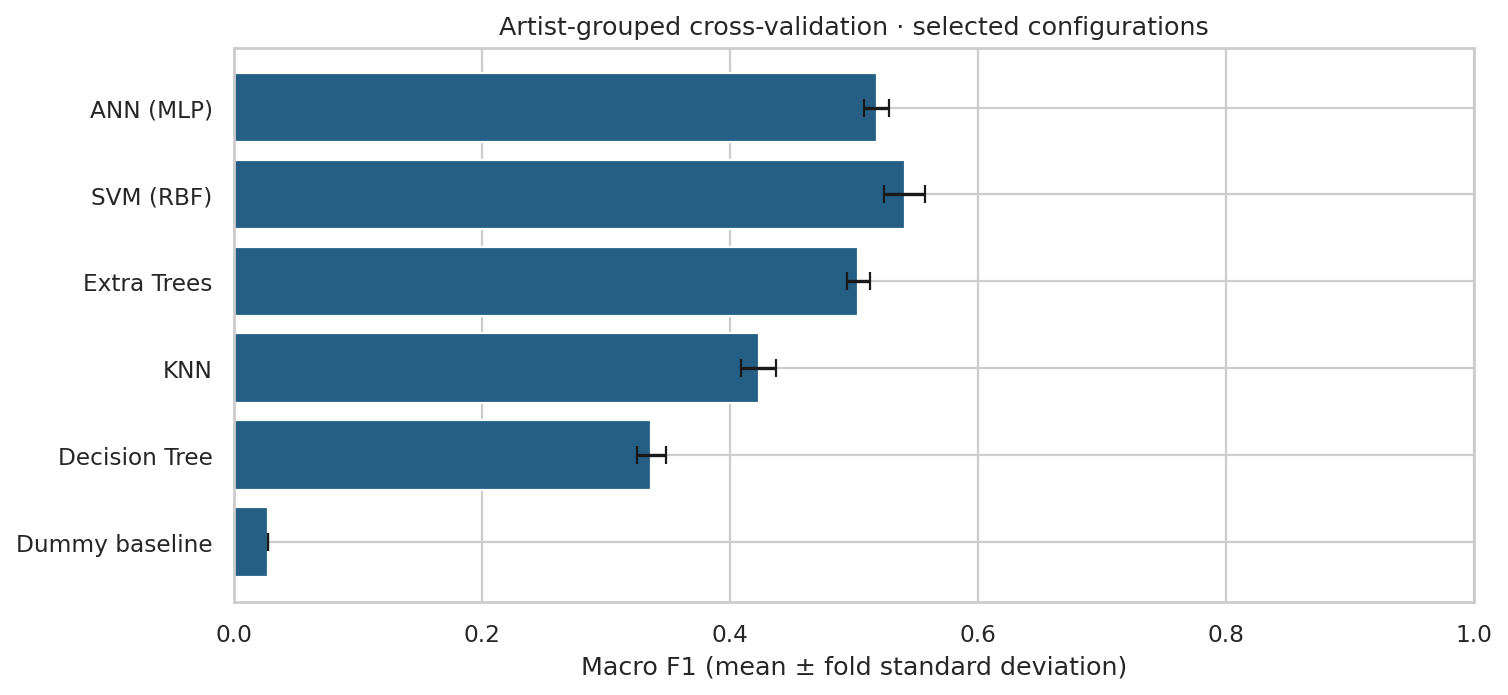

,model,test_accuracy,test_f1_macro,original_test_accuracy,original_test_f1
0,ANN (MLP),0.4725,0.4695,0.4588,0.4546
1,SVM (RBF),0.4975,0.4925,0.4912,0.4885
2,Extra Trees,0.4812,0.4760,NaN,NaN
3,KNN,0.3825,0.3674,0.3338,0.3287
4,Decision Tree,0.3425,0.3437,0.3425,0.3437
5,Dummy baseline,0.1250,0.0278,0.1250,0.0278


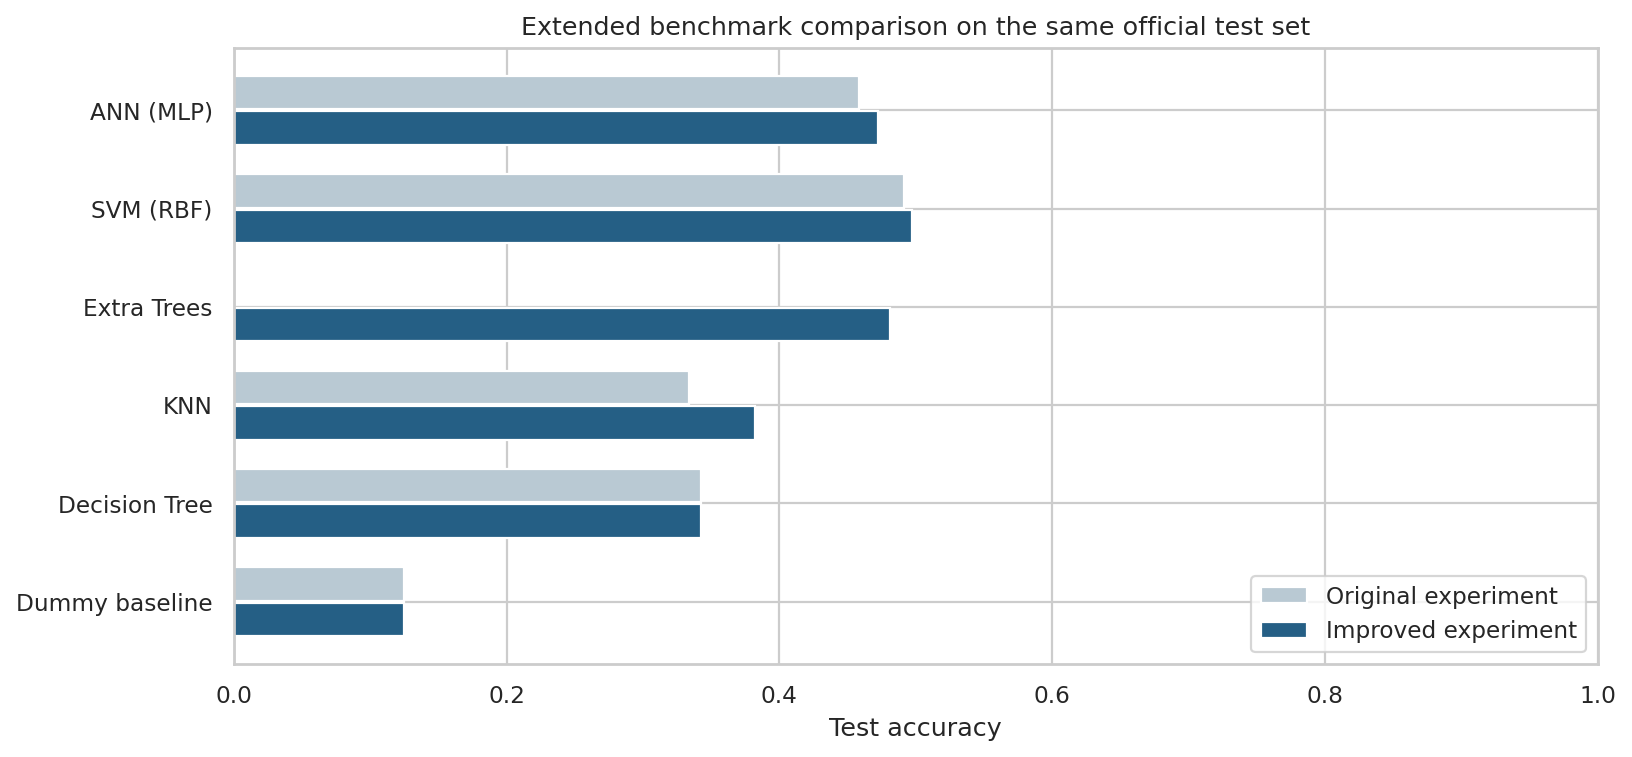

In [6]:
if run_info["profile"] == "improved":
    cv_results = pd.read_csv(REPORTS / "cv_results.csv")
    display(cv_results.sort_values("cv_mean_f1", ascending=False).head(10))
    cv_audit = json.loads((REPORTS / "cv_splits.json").read_text())
    if isinstance(cv_audit, list):
        display(pd.DataFrame([{
            "fold": row["fold"], "fitting tracks": len(row["fit_track_ids"]),
            "assessment tracks": len(row["validation_track_ids"]),
            "shared artists": row["artist_overlap"],
        } for row in cv_audit]))
        assert all(row["artist_overlap"] == 0 for row in cv_audit)
    display(FileLink("../reports/cv_splits.json", result_html_prefix="Full fold membership and artist-overlap audit: "))
    display(pd.read_csv(REPORTS / "ann_seed_results.csv"))
    display(Image(filename=str(REPORTS / "figures/grouped_cv.png"), width=1000))
    baseline_file = ROOT / "baseline/reports/model_comparison.csv"
    if baseline_file.exists():
        old = pd.read_csv(baseline_file)
        before = old[["model", "test_accuracy", "test_f1_macro"]].rename(columns={
            "test_accuracy": "original_test_accuracy", "test_f1_macro": "original_test_f1"})
        after = comparison[["model", "test_accuracy", "test_f1_macro"]]
        display(after.merge(before, on="model", how="left").round(4))
        display(Image(filename=str(REPORTS / "figures/improvement_comparison.png"), width=1050))


### 5. Inspect genre-specific errors

Accuracy summarizes correct labels. Macro F1 gives every genre equal weight. A confusion matrix reveals which genres are confused, while per-class precision and recall distinguish false positives from missed examples.

In the plots, each matrix row is the actual genre and each column is a predicted genre. Each row is normalized to 100%. Inspect the recorded values before proposing reasons for an error.

,precision,recall,f1-score,support
Electronic,0.5816,0.57,0.5758,100.0
Experimental,0.3303,0.36,0.3445,100.0
Folk,0.1705,0.15,0.1596,100.0
Hip-Hop,0.6207,0.72,0.6667,100.0
Instrumental,0.4875,0.39,0.4333,100.0
International,0.5851,0.55,0.5670,100.0
Pop,0.3966,0.46,0.4259,100.0
Rock,0.5859,0.58,0.5829,100.0


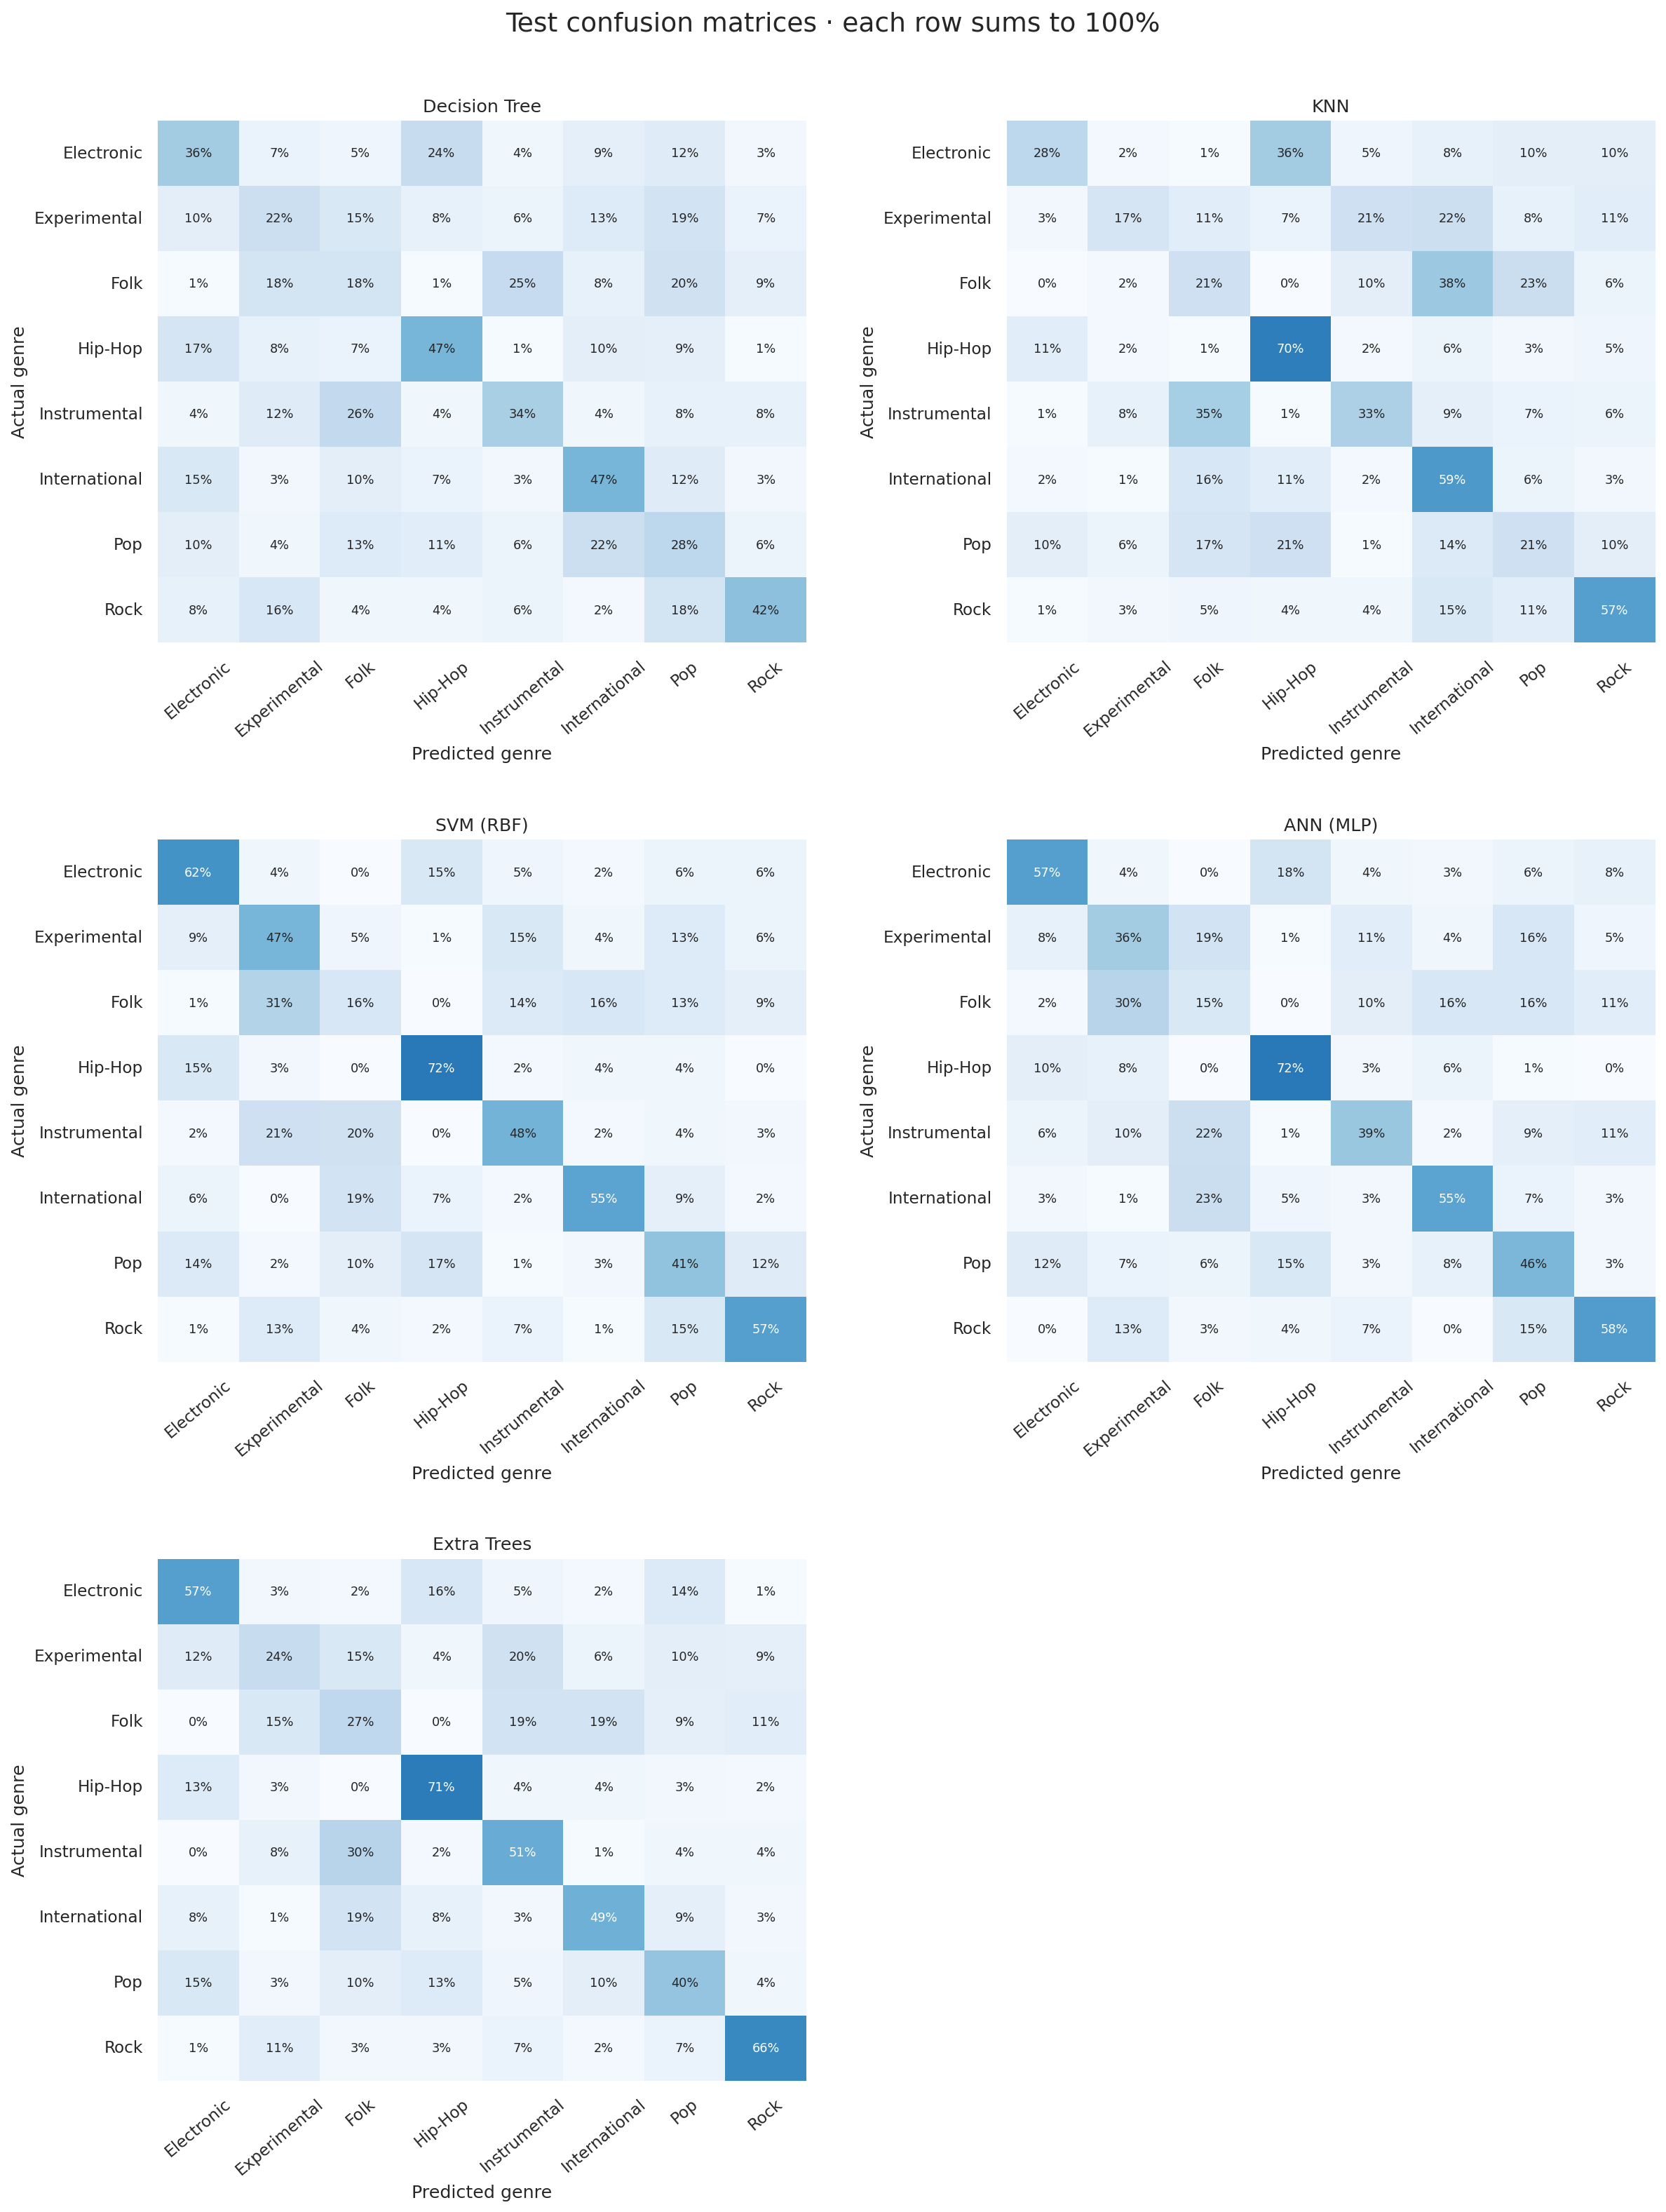

,track_id,actual,artist_id,artist,title,decision_tree,knn,svm,ann,extra_trees,dummy
0,182,Rock,64,Ariel Pink's Haunted Graffiti,Jules Lost His Jewels,Rock,International,Pop,Pop,Pop,Electronic
1,704,International,140,Fósforo,Mano De Dios,International,Hip-Hop,Hip-Hop,International,Hip-Hop,Electronic
2,705,International,140,Fósforo,Tio Cocodrilo,Pop,Hip-Hop,Electronic,International,Hip-Hop,Electronic
3,706,International,140,Fósforo,Esto Es Califas,Hip-Hop,Hip-Hop,Hip-Hop,Hip-Hop,Hip-Hop,Electronic
4,707,International,140,Fósforo,Cochabamba,Pop,Pop,Pop,Rock,Pop,Electronic


In [7]:
classification = json.loads((REPORTS / "classification_reports.json").read_text())
champion_report = classification[selection["champion"]]
genre_scores = pd.DataFrame({
    label: champion_report[label] for label in dataset.manifest["genres"]
}).T
display(genre_scores.round(4))
display(Image(filename=str(REPORTS / "figures/confusion_matrices.png"), width=1100))
test_predictions = pd.read_csv(REPORTS / "test_predictions.csv")
display(test_predictions.head())


### 6. Which audio features matter?

Grouped permutation importance jointly shuffles all columns in one feature family across validation tracks. It measures the resulting drop in macro F1 for the selected **training-only** model. Five repeats produce a mean and a descriptive standard deviation.

Joint shuffling preserves within-family relationships. Larger groups have more columns, and correlated groups can substitute for one another. These scores describe model reliance rather than musical causality. The displayed training-only ANOVA ranking is a descriptive view; any ANOVA selector used by an improved classifier is independently fitted inside each training fold, then on the final fitting partition.

,family,n_features,mean_f1_drop,std_f1_drop
0,mfcc,140,0.2446,0.0053
1,spectral_contrast,49,0.1617,0.0089
2,chroma_cqt,84,0.0781,0.0090
3,chroma_cens,84,0.0537,0.0081
4,tonnetz,42,0.0489,0.0121
5,chroma_stft,84,0.0471,0.0129
6,rmse,7,0.0317,0.0115
7,spectral_bandwidth,7,0.0305,0.0051
8,zcr,7,0.0198,0.0081
9,spectral_rolloff,7,0.0157,0.0036


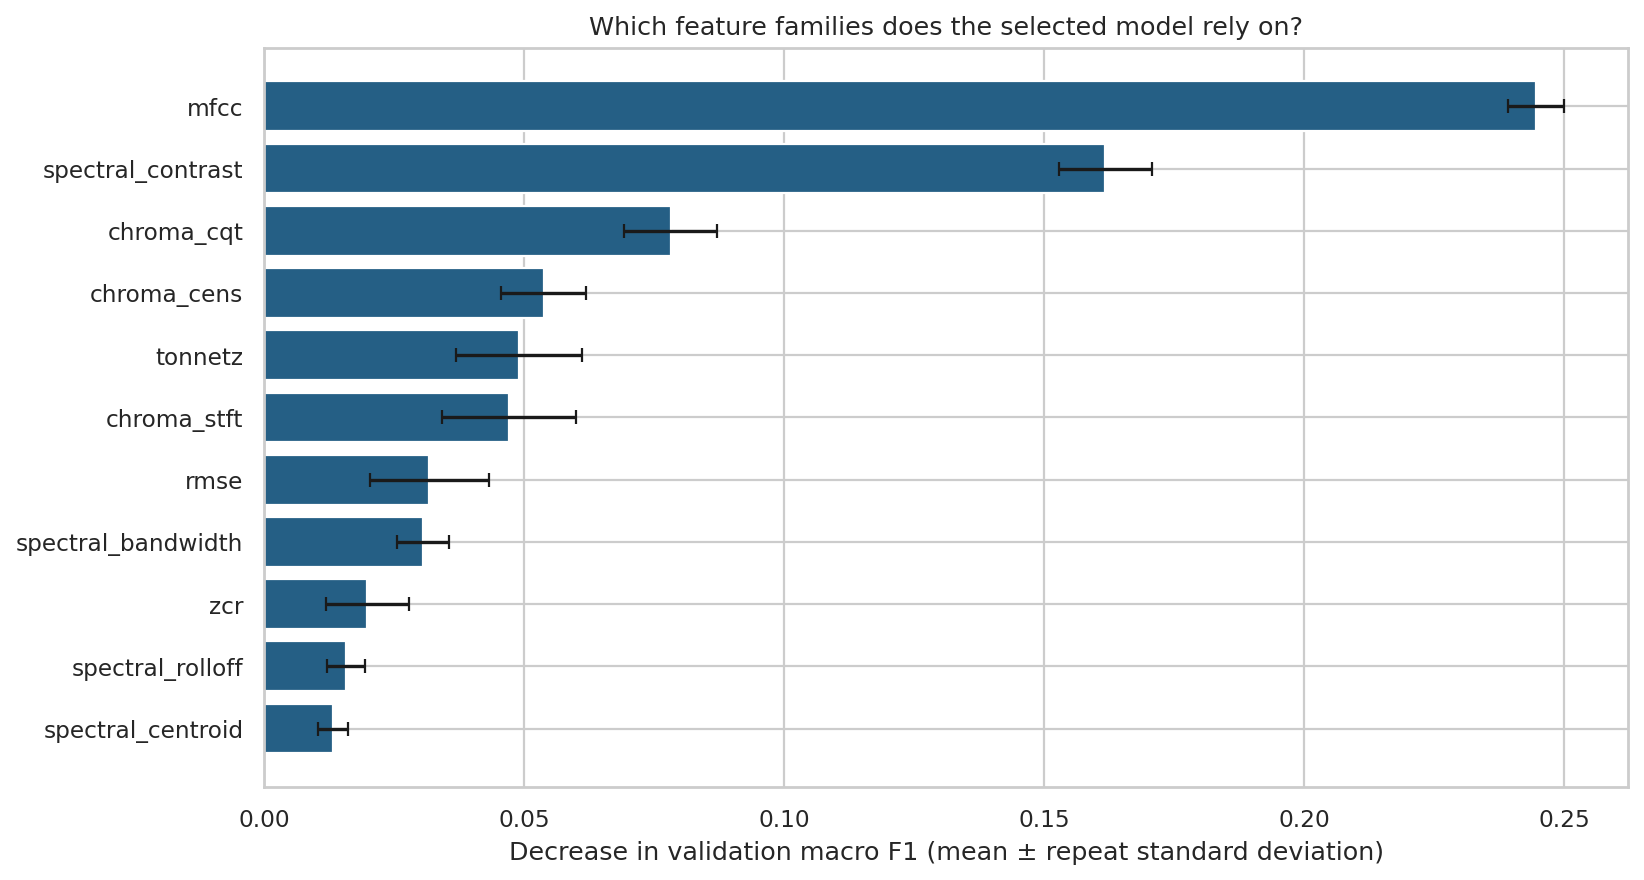

,feature,training_anova_f,training_anova_p
0,mfcc__mean__01,306.954294,0.0
1,mfcc__median__01,305.920322,0.0
2,spectral_contrast__median__02,269.075438,0.0
3,spectral_contrast__mean__02,265.720632,0.0
4,mfcc__mean__03,256.955546,0.0
5,spectral_contrast__mean__04,253.609970,0.0
6,spectral_contrast__median__04,251.710021,0.0
7,mfcc__median__03,250.850887,0.0
8,spectral_rolloff__mean__01,249.547128,0.0
9,spectral_contrast__median__03,248.583851,0.0


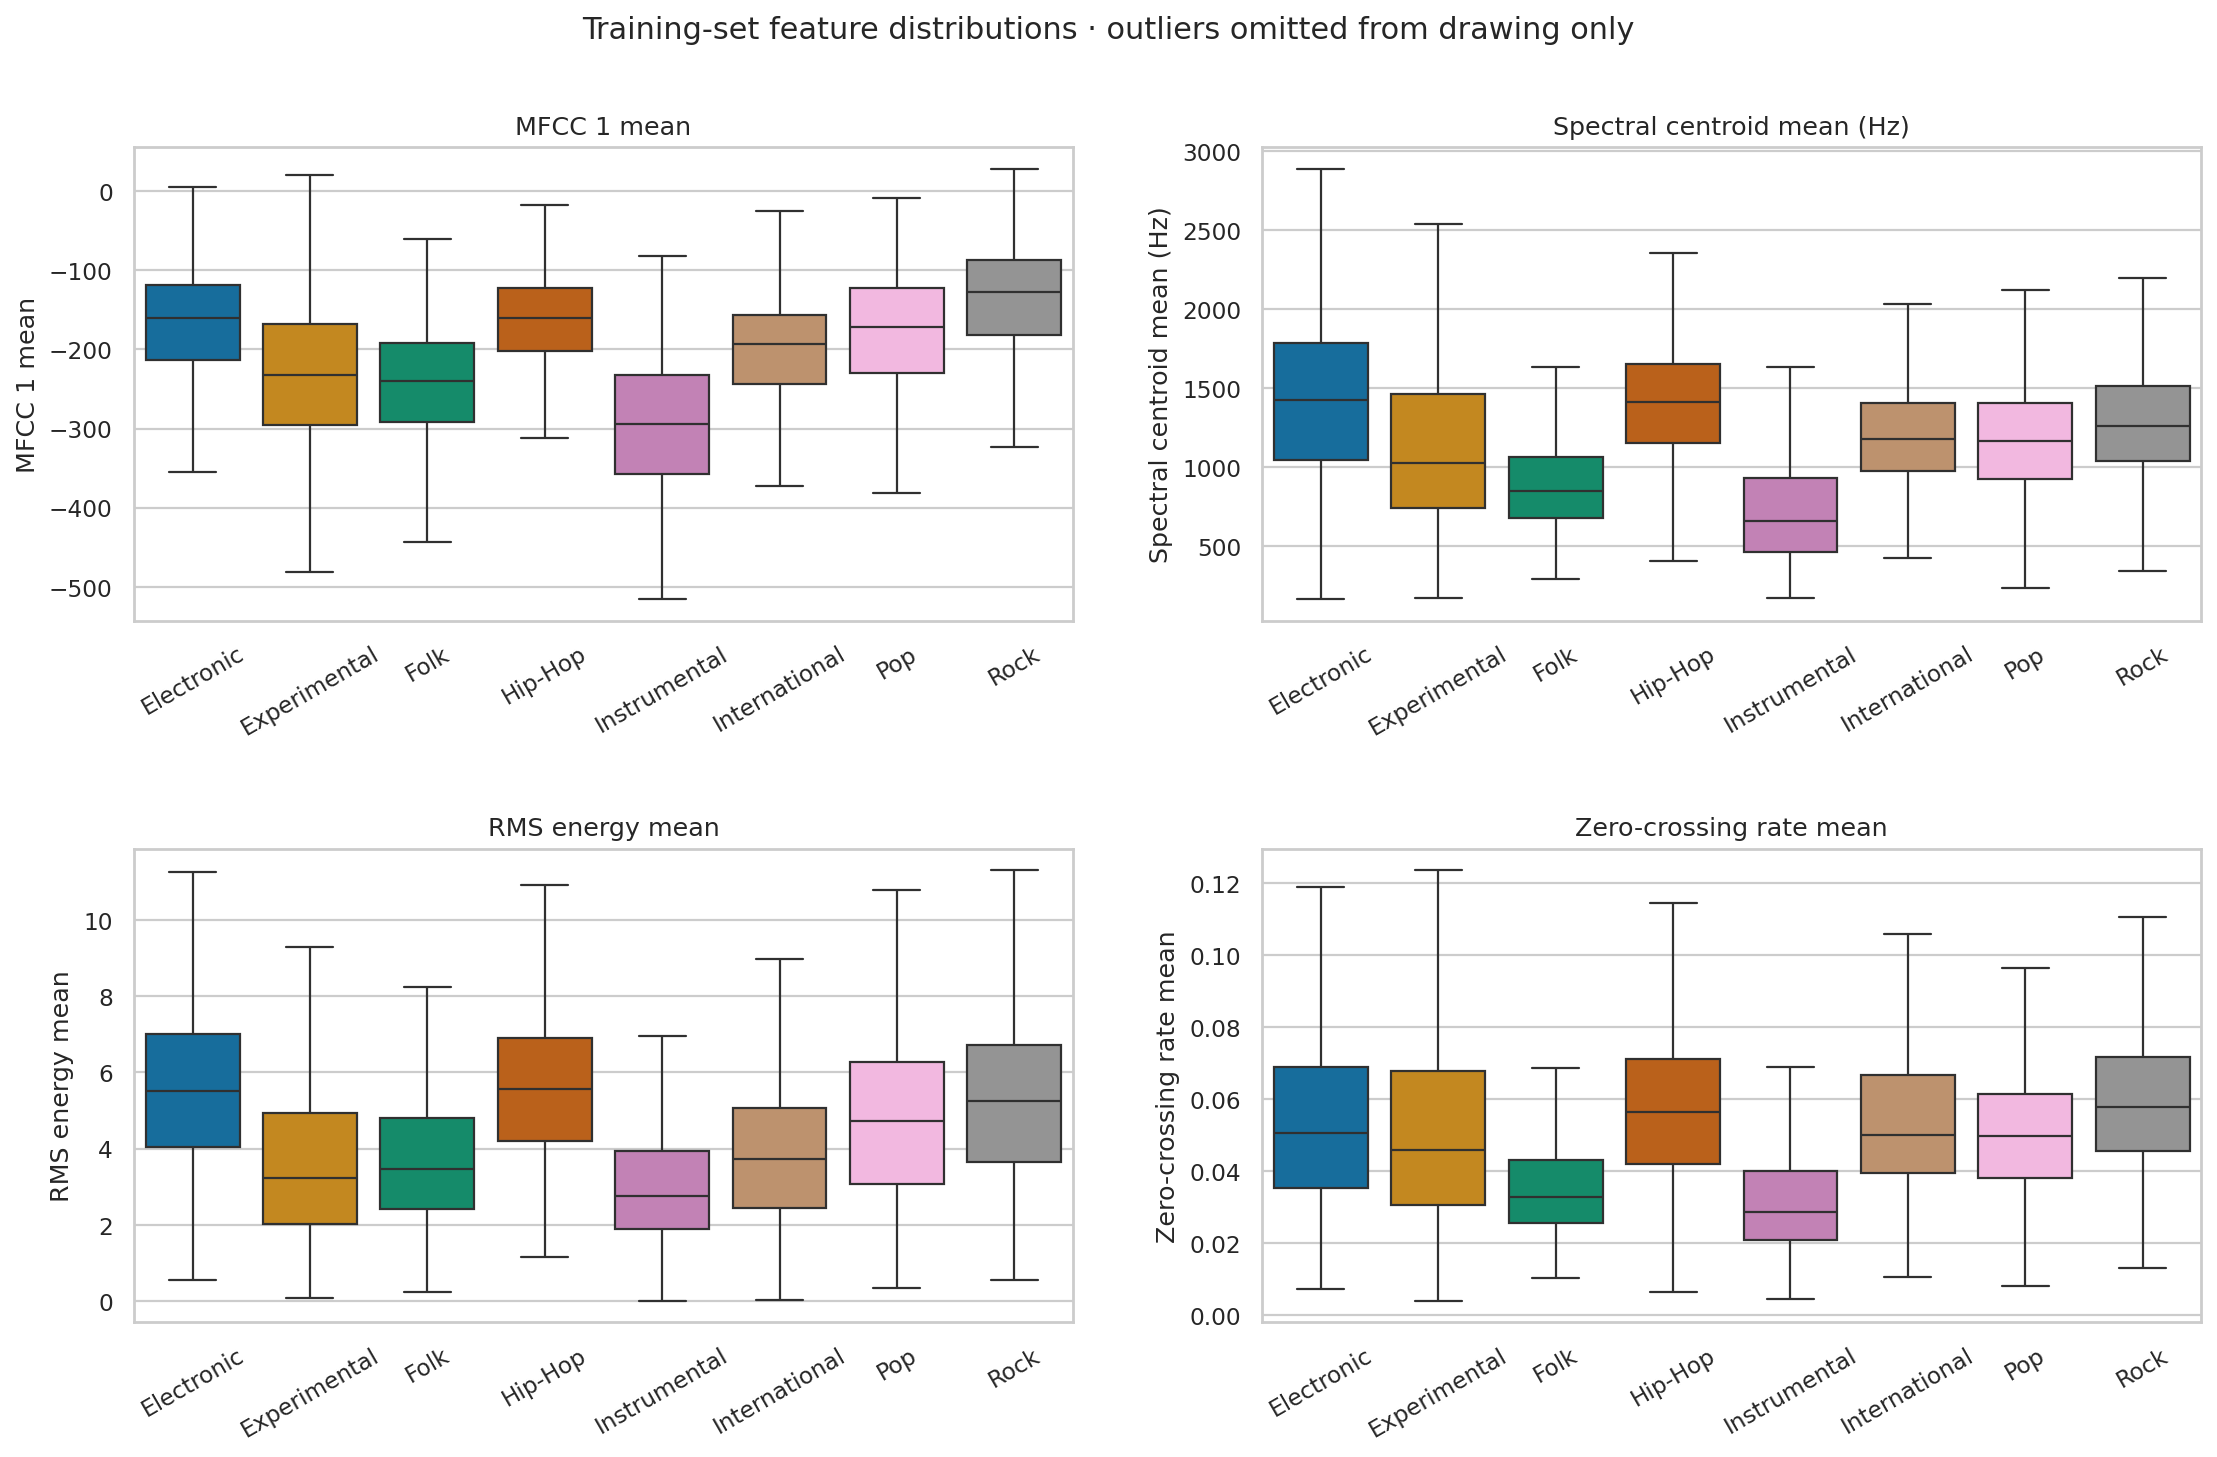

In [8]:
importance = pd.read_csv(REPORTS / "feature_family_importance.csv")
display(importance[["family", "n_features", "mean_f1_drop", "std_f1_drop"]].round(4))
display(Image(filename=str(REPORTS / "figures/feature_importance.png"), width=950))
display(pd.read_csv(REPORTS / "training_feature_associations.csv").head(10))
display(Image(filename=str(REPORTS / "figures/feature_distributions.png"), width=1100))


### 7. Build a music similarity map with PCA

Fit preprocessing and PCA on training features only, then project validation tracks. Genre labels are used only to color the map. The first two components make a drawing; 50 components form the similarity/clustering representation.

Check explained variance before interpreting the drawing. Nearby 2D points can differ in discarded dimensions, and separated colors do not constitute a classification accuracy measurement. The HTML map supports hover details, legend filtering, and zoom.

,fraction
Variance retained by first 2 PCs,0.189108
Variance retained by first 50 PCs,0.715907


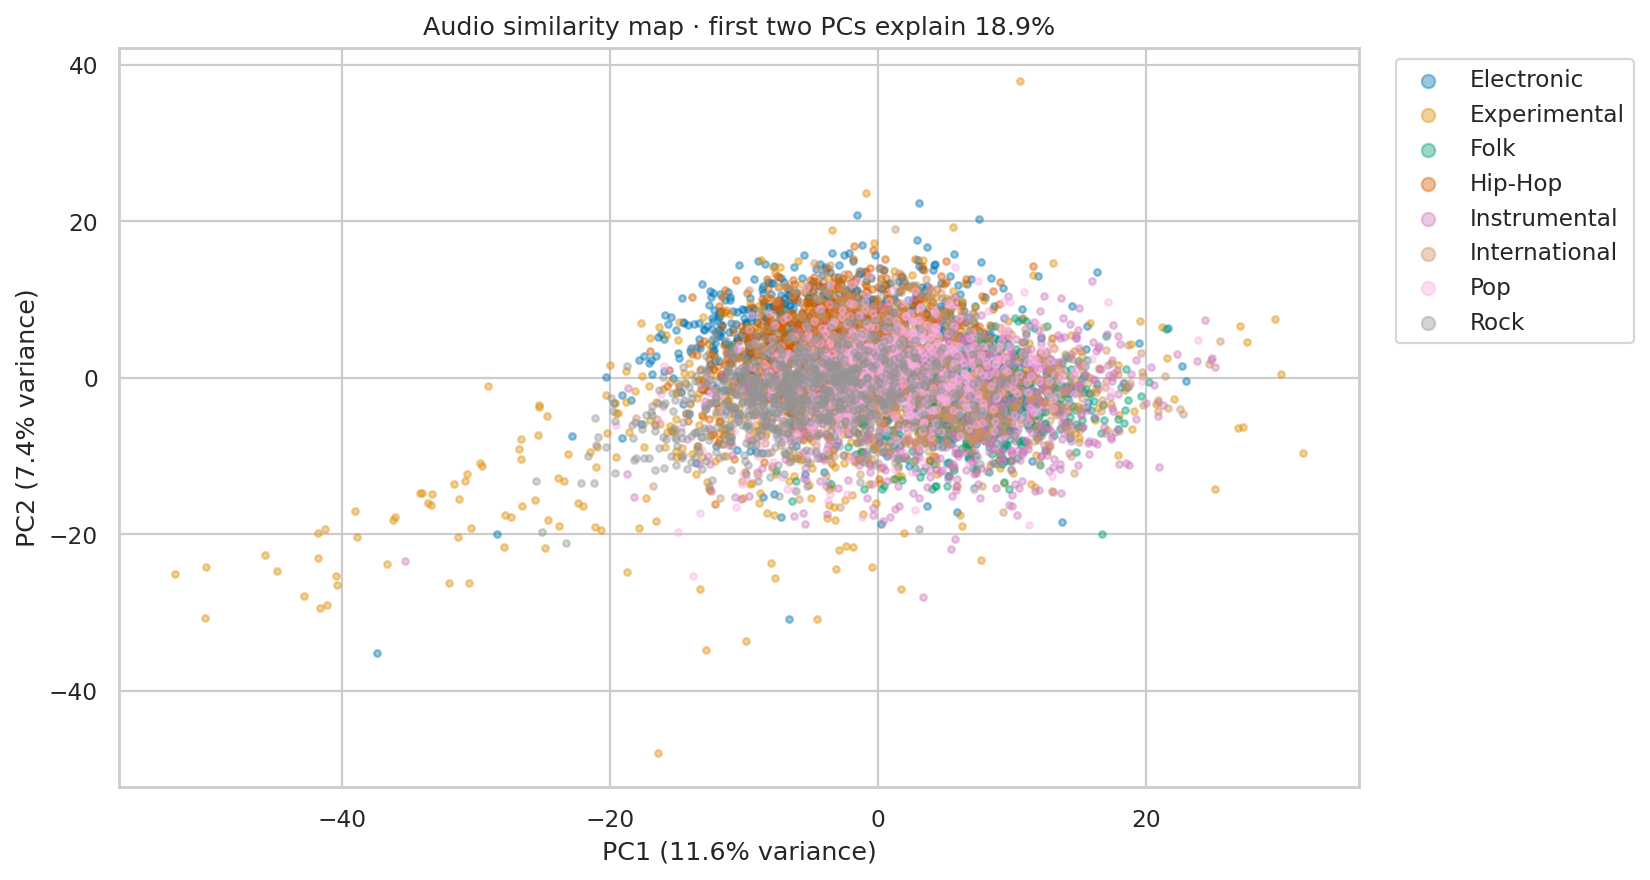

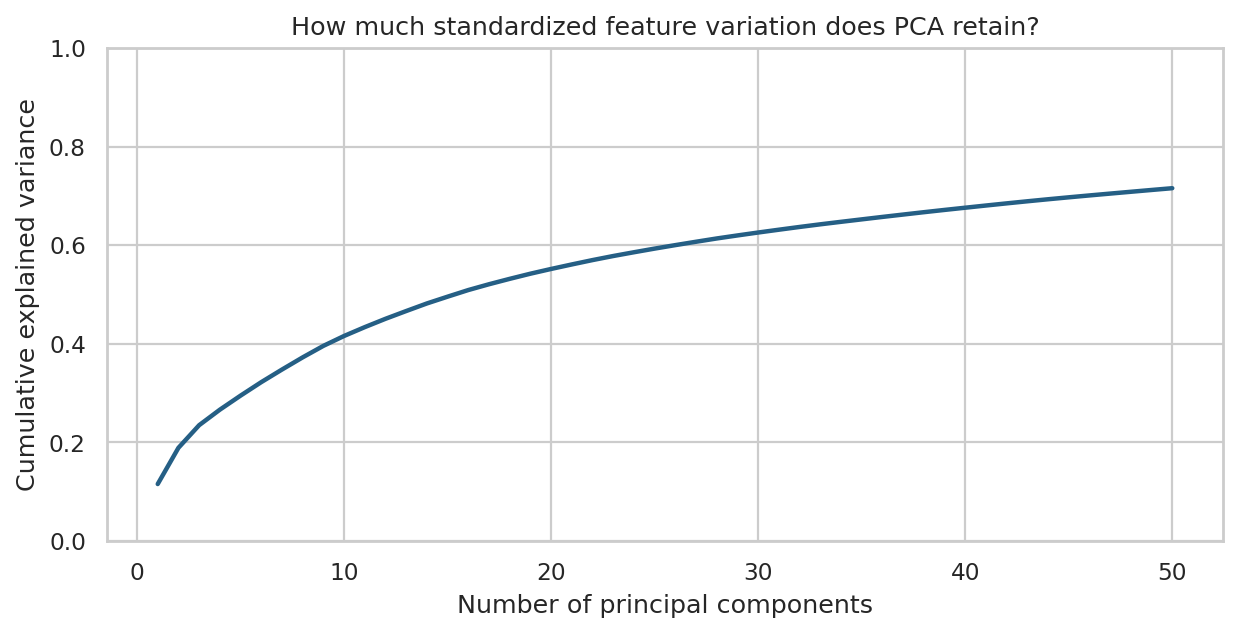

/workspace/musicmap/reports/song_map.html

In [9]:
discovery = json.loads((REPORTS / "discovery_summary.json").read_text())
display(pd.Series({
    "Variance retained by first 2 PCs": discovery["pca_2d_explained_variance"],
    "Variance retained by first 50 PCs": discovery["pca_50d_explained_variance"],
}).to_frame("fraction"))
display(Image(filename=str(REPORTS / "figures/pca_map.png"), width=950))
display(Image(filename=str(REPORTS / "figures/pca_variance.png"), width=850))
display(FileLink("../reports/song_map.html", result_html_prefix="Interactive map: "))


### 8. Discover clusters with K-means

Fit K-means on the training set's 50-dimensional PCA representation with k = 8 fixed in advance. Assign validation tracks to the learned centroids. Genres do not enter fitting.

Adjusted Rand index (ARI) and normalized mutual information (NMI) measure agreement with supplied genres. Silhouette measures geometric separation. These are distinct questions. Cluster IDs are arbitrary: cluster 0 is not genre 0. The test set is excluded from discovery.

,score
Validation adjusted Rand index,0.140279
Validation normalized mutual information,0.224417
Validation silhouette,0.040551


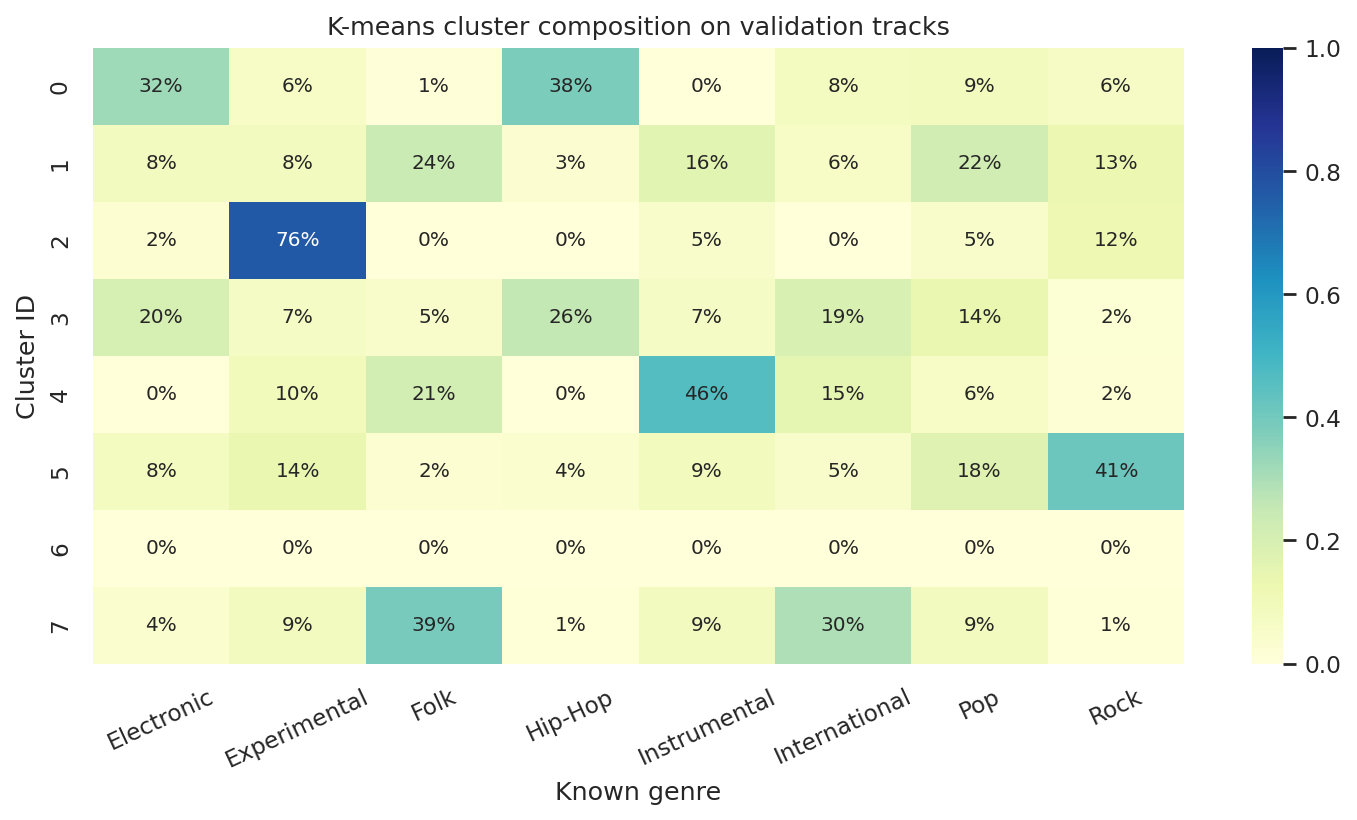

In [10]:
display(pd.Series({
    "Validation adjusted Rand index": discovery["kmeans_adjusted_rand_index"],
    "Validation normalized mutual information": discovery["kmeans_normalized_mutual_information"],
    "Validation silhouette": discovery["kmeans_silhouette"],
}).to_frame("score"))
display(Image(filename=str(REPORTS / "figures/cluster_composition.png"), width=1000))


### 9. Retrieve similar songs

Measure Euclidean distance in the train-fitted PCA space and search the training catalog. By default, exclude the query and all tracks with the same artist ID. Show genre labels for interpretation; they do not contribute to distance.

This demonstrates descriptor-based audio similarity. It does not measure personal taste.

In [11]:
query_id = int(validation_ids[0])
display(dataset.metadata.loc[[query_id], ["title", "artist", "genre", "split"]])
with threadpool_limits(limits=THREADS):
    similar = nearest_tracks(dataset, ROOT / "models", query_id, k=5)
assert set(similar["split"]) == {"training"}
assert query_id not in similar.index
display(similar)


,title,artist,genre,split
track_id,,,,
148,Blackout 2,Contradiction,Experimental,validation


,title,artist,genre,split,distance
track_id,,,,,
12537,Maree Lunaire,Smoking After,Pop,training,14.826061
127297,The Pursuit of Unintentional Humor,"Oh Yeah, the Future",Pop,training,15.138597
145730,STOCKPILE! (Funky Dubb Mixx),LOWdown,Hip-Hop,training,15.160879
113972,Your Pulse,Little Glass Men,Electronic,training,15.226601
98838,intense,Moonove,Electronic,training,15.547279


### 10. Use the saved final classifier

The saved model is the validation-selected configuration refitted on training plus validation. The following uses one recorded test track as an illustration, not as new independent evaluation evidence. For performance claims, use the full test metrics above.

A matching flat CSV of precomputed descriptors can also be passed to the command-line predictor. Raw MP3 descriptor extraction requires a separately validated pipeline compatible with the original FMA features.

In [12]:
model = joblib.load(ROOT / "models/best_model.joblib")
example_id = int(dataset.ids("test")[0])
with threadpool_limits(limits=THREADS):
    predicted_genre = model.predict(dataset.X.loc[[example_id]])[0]
display(pd.DataFrame([{
    "track_id": example_id,
    "title": dataset.metadata.at[example_id, "title"],
    "actual_genre": dataset.y.at[example_id],
    "predicted_genre": predicted_genre,
    "partition": "test",
}]))


,track_id,title,actual_genre,predicted_genre,partition
0,182,Jules Lost His Jewels,Rock,Pop,test


### 11. Reproducibility and report

The project saves every validation candidate, the pre-test selection, all test predictions, raw confusion counts, fitted pipelines, source checksums, dependency versions, and random seeds.

The Markdown, HTML, and editable Word reports are generated from these saved measurements. Fill in your academic details and adapt the report to your instructor's format. The presentation outline and viva guide help you explain your work.

In [13]:
display(pd.Series({
    "Python": run_info["python"],
    "scikit-learn": run_info["versions"]["scikit-learn"],
    "Candidate count including dummy": run_info["candidate_count"],
    "Experiment seconds excluding preparation/discovery": round(run_info["elapsed_seconds"], 1),
    "Numerical-library threads": run_info["threads"],
}).to_frame("recorded value"))
display(FileLink("../reports/MusicMap_Report.html", result_html_prefix="Report: "))
display(FileLink("../reports/MusicMap_Report.docx", result_html_prefix="Editable Word report: "))
display(FileLink("../reports/presentation_outline.md", result_html_prefix="Presentation guide: "))
display(FileLink("../docs/VIVA.md", result_html_prefix="Viva preparation: "))


,recorded value
Python,3.12.14
scikit-learn,1.8.0
Candidate count including dummy,94
Experiment seconds excluding preparation/discovery,1182.5
Numerical-library threads,2


/workspace/musicmap/reports/MusicMap_Report.html

/workspace/musicmap/reports/MusicMap_Report.docx

/workspace/musicmap/reports/presentation_outline.md

/workspace/musicmap/docs/VIVA.md

### Conclusions to explain in your own words

1. State the validation-selected model and its actual test accuracy and macro F1.
2. Compare it with the majority-class baseline and describe the biggest observed genre confusions.
3. Explain why artist-disjoint evaluation and training-fitted scaling matter.
4. Interpret the leading feature families without treating importance as causality.
5. Distinguish classifier accuracy, cluster agreement, and geometric similarity.
6. Explain what variance the 2D PCA map retains and what it omits.
7. Identify the limits: eight genres, a finite search, limited ANN seeds, summary descriptors, and a previously viewed official test set. Explain why a fresh confirmation dataset remains useful.

**Reference:** Defferrard, M., Benzi, K., Vandergheynst, P., and Bresson, X. (2017). *FMA: A Dataset for Music Analysis*. ISMIR. [Paper](https://arxiv.org/abs/1612.01840), [dataset repository](https://github.com/mdeff/fma). FMA metadata and derived features: CC BY 4.0.